# Maaş Tahmini — Skor İyileştirme ve Model Karşılaştırması

**Amaç:** Derste kurulan Linear Regression modelinin skorunu (R² = 0.666) artırmak ve farklı regresyon modellerini karşılaştırmak.

**Plan:**
1. Dersteki baseline'ı birebir tekrar üretmek
2. Veriyi incelemek ve hataları bulmak
3. Veri temizliği ve doğru kodlama (encoding)
4. Yeni özellikler üretmek (feature engineering)
5. Farklı modelleri denemek ve karşılaştırmak
6. Cross-validation ile sonuçları doğrulamak
7. Tekrar eden satırlar (data leakage) kontrolü
8. Sonuç ve yorum

## 0. Kütüphaneler ve veri

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

RANDOM_STATE = 42
raw = pd.read_csv("Salary_Data.csv")
raw.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


## 1. Baseline: dersteki modelin tekrarı

Derste yapılan adımların aynısı: eksikleri sil → LabelEncoder → IQR ile aykırı değer temizliği → `Age` sütununu sil → %80/%20 ayır → ölçekle → Linear Regression.

Bu hücrenin amacı başlangıç noktasını doğrulamak: **R² ≈ 0.666** çıkmalı.

In [2]:
df_base = raw.dropna().copy()
le = LabelEncoder()
for c in ["Gender", "Education Level", "Job Title"]:
    df_base[c] = le.fit_transform(df_base[c])

q1, q3 = df_base["Salary"].quantile([0.25, 0.75])
iqr = q3 - q1
df_base = df_base[(df_base["Salary"] > q1 - 1.5 * iqr) & (df_base["Salary"] < q3 + 1.5 * iqr)]
df_base = df_base.drop(columns=["Age"])

Xb = df_base.drop(columns=["Salary"]); yb = df_base["Salary"]
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.2, random_state=RANDOM_STATE)
sc = StandardScaler().fit(Xb_tr)
lr_base = LinearRegression().fit(sc.transform(Xb_tr), yb_tr)
pb = lr_base.predict(sc.transform(Xb_te))

baseline = {"R2": r2_score(yb_te, pb), "MAE": mean_absolute_error(yb_te, pb),
            "RMSE": np.sqrt(mean_squared_error(yb_te, pb))}
print(f"Baseline  R2 = {baseline['R2']:.4f} | MAE = {baseline['MAE']:,.0f} | RMSE = {baseline['RMSE']:,.0f}")

Baseline  R2 = 0.6656 | MAE = 24,448 | RMSE = 30,881


## 2. Veriyi incelemek: baseline'daki sorunlar

Baseline'ın düşük kalmasının dört nedeni var. Aşağıda her birini gösteriyoruz.

### 2.1 Eğitim seviyesi aynı kategoriyi farklı yazıyor

In [3]:
raw["Education Level"].value_counts(dropna=False)

Education Level
Bachelor's Degree    2267
Master's Degree      1573
PhD                  1368
Bachelor's            756
High School           448
Master's              288
NaN                     3
phD                     1
Name: count, dtype: int64

`Bachelor's` ile `Bachelor's Degree`, `Master's` ile `Master's Degree`, `PhD` ile `phD` aynı şey. Model bunları 7 farklı kategori sanıyor; gerçekte 4 kategori var.

Ayrıca `LabelEncoder` kategorileri **alfabetik** numaralandırıyor. Bu yüzden "High School" "Bachelor's"tan büyük bir sayı alıyor. Eğitim **sıralı** bir değişken (Lise < Lisans < Yüksek Lisans < Doktora), o sırayla kodlanmalı.

### 2.2 Job Title için LabelEncoder doğrusal model için anlamsız

In [4]:
print("Farklı unvan sayısı:", raw["Job Title"].nunique())
raw.dropna().groupby("Job Title")["Salary"].mean().sort_values().iloc[[0, 1, 2, -3, -2, -1]]

Farklı unvan sayısı: 193


Job Title
Junior Business Operations Analyst     17675.0
Receptionist                           25000.0
Delivery Driver                        28000.0
Chief Data Officer                    220000.0
Chief Technology Officer              250000.0
CEO                                   250000.0
Name: Salary, dtype: float64

193 unvana 0–192 arası rastgele numara verildiğinde Linear Regression "numara büyüdükçe maaş artar" gibi bir ilişki arıyor. Böyle bir ilişki yok, ama unvan maaşı çok iyi açıklıyor. Doğru yöntem **one-hot encoding**: her unvan için ayrı bir 0/1 sütunu.

### 2.3 Age silinmiş

In [5]:
raw[["Age", "Years of Experience", "Salary"]].corr().round(3)

,Age,Years of Experience,Salary
Age,1.000,0.938,0.728
Years of Experience,0.938,1.000,0.809
Salary,0.728,0.809,1.000


`Age`, deneyimle 0.94 korele olduğu için silinmiş. Bu, katsayı yorumunu bozar ama tahmin gücünü genelde düşürmez. Atmak bilgi kaybı oldu, geri ekliyoruz.

### 2.4 Tekrar eden satırlar

In [6]:
n_dup = raw.duplicated().sum()
print(f"Toplam satır: {len(raw)} | Birebir tekrar eden: {n_dup} (%{100*n_dup/len(raw):.0f})")

Toplam satır: 6704 | Birebir tekrar eden: 4912 (%73)


Bu çok önemli bir bulgu. Etkisini **Bölüm 7**'de ayrıca inceliyoruz.

## 3. Veri temizliği ve doğru kodlama

In [7]:
df = raw.dropna().copy()

# Eğitim: yazım farklarını birleştir, sıralı kodla
df["Education Level"] = df["Education Level"].replace(
    {"Bachelor's Degree": "Bachelor's", "Master's Degree": "Master's", "phD": "PhD"})
edu_order = {"High School": 0, "Bachelor's": 1, "Master's": 2, "PhD": 3}
df["Edu"] = df["Education Level"].map(edu_order)

# Cinsiyet: one-hot (Male / Female / Other)
df = pd.concat([df, pd.get_dummies(df["Gender"], prefix="G", drop_first=True).astype(int)], axis=1)

print(df["Education Level"].value_counts())
df.head()

Education Level
Bachelor's     3021
Master's       1860
PhD            1369
High School     448
Name: count, dtype: int64


,Age,Gender,Education Level,Job Title,Years of Experience,Salary,Edu,G_Male,G_Other
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0,1,1,0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0,2,0,0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0,3,1,0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0,1,0,0
4,52.0,Male,Master's,Director,20.0,200000.0,2,1,0


## 4. Feature engineering (yeni özellikler)

- **Kıdem bayrakları:** Unvanın içindeki "Senior", "Junior", "Manager", "Director/VP/Chief" kelimeleri maaş hakkında bilgi taşır. Bunları ayrı 0/1 sütunlarına çıkarıyoruz.
- **Deneyim²:** Maaş deneyimle doğrusal değil, başta hızlı sonra yavaş artıyor. Karesini eklemek doğrusal modelin bu eğriyi yakalamasını sağlar.
- **Job Title one-hot:** Her unvan için ayrı sütun.

In [8]:
t = df["Job Title"].str.lower()
df["Senior"]   = t.str.contains(r"\bsenior\b|\bsr\b").astype(int)
df["Junior"]   = t.str.contains(r"junior|juniour").astype(int)
df["Manager"]  = t.str.contains("manager").astype(int)
df["Director"] = t.str.contains(r"director|\bvp\b|chief|ceo|cto").astype(int)
df["Exp2"]     = df["Years of Experience"] ** 2

job_oh = pd.get_dummies(df["Job Title"], prefix="Job", drop_first=True).astype(int)

num_cols = ["Age", "Years of Experience", "Exp2", "Edu", "Senior", "Junior", "Manager", "Director"] \
           + [c for c in df.columns if c.startswith("G_")]
X_small = df[num_cols]                                  # unvanı sadece bayraklarla temsil eden set
X_full  = pd.concat([df[num_cols], job_oh], axis=1)     # unvanı one-hot ile ekleyen tam set
y = df["Salary"]
print("Küçük set:", X_small.shape, "| Tam set:", X_full.shape)

Küçük set: (6698, 10) | Tam set: (6698, 200)


## 5. Adım adım iyileştirme (Linear Regression)

Her adımın skora katkısını ayrı ayrı görmek için aynı split (random_state=42) ile ölçüyoruz.

In [9]:
def evaluate(model, X, y, name):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
    model.fit(Xtr, ytr)
    p = model.predict(Xte)
    return {"Adım / Model": name, "R2": r2_score(yte, p),
            "MAE": mean_absolute_error(yte, p), "RMSE": np.sqrt(mean_squared_error(yte, p))}

steps = [{"Adım / Model": "0) Baseline (ders)", **baseline}]
steps.append(evaluate(LinearRegression(), df[["Edu", "Years of Experience"] + [c for c in df.columns if c.startswith("G_")]], y,
                      "1) Eğitim temizlendi (Age yok, unvan yok)"))
steps.append(evaluate(LinearRegression(), df[["Age", "Edu", "Years of Experience", "Exp2"] + [c for c in df.columns if c.startswith("G_")]], y,
                      "2) + Age + Deneyim²"))
steps.append(evaluate(LinearRegression(), X_small, y, "3) + Kıdem bayrakları"))
steps.append(evaluate(LinearRegression(), X_full, y, "4) + Job Title one-hot"))

steps_df = pd.DataFrame(steps).set_index("Adım / Model")
steps_df.style.format({"R2": "{:.3f}", "MAE": "{:,.0f}", "RMSE": "{:,.0f}"})

,R2,MAE,RMSE
Adım / Model,,,
0) Baseline (ders),0.666,"24,448","30,881"
"1) Eğitim temizlendi (Age yok, unvan yok)",0.696,"22,940","29,424"
2) + Age + Deneyim²,0.780,"19,525","25,037"
3) + Kıdem bayrakları,0.797,"18,927","24,067"
4) + Job Title one-hot,0.881,"13,289","18,389"


## 6. Model karşılaştırması

Beş regresyon modeli, aynı tam özellik seti ile:

| Model | Kısaca |
|---|---|
| Linear Regression | Düz bir formül: her özelliğe bir ağırlık |
| KNN | Benzer kişilerin maaş ortalaması (ölçekleme gerekir) |
| Decision Tree | Evet/hayır sorularıyla veriyi bölen tek bir ağaç |
| Random Forest | Yüzlerce ağacın ortalaması |
| Gradient Boosting | Her ağacın bir öncekinin hatasını düzelttiği zincir |

In [10]:
models = {
    "Linear Regression": LinearRegression(),
    "KNN (k=5)":         make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
    "Decision Tree":     DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest":     RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=500, max_depth=4, learning_rate=0.05, random_state=RANDOM_STATE),
}
results = pd.DataFrame([evaluate(m, X_full, y, n) for n, m in models.items()]).set_index("Adım / Model")
results.loc["Baseline (ders)"] = baseline
results = results.sort_values("R2", ascending=False)
results.style.format({"R2": "{:.3f}", "MAE": "{:,.0f}", "RMSE": "{:,.0f}"})

,R2,MAE,RMSE
Adım / Model,,,
Random Forest,0.975,"3,169","8,433"
Decision Tree,0.970,"3,116","9,223"
Gradient Boosting,0.953,"7,764","11,552"
KNN (k=5),0.947,"4,998","12,345"
Linear Regression,0.881,"13,289","18,389"
Baseline (ders),0.666,"24,448","30,881"


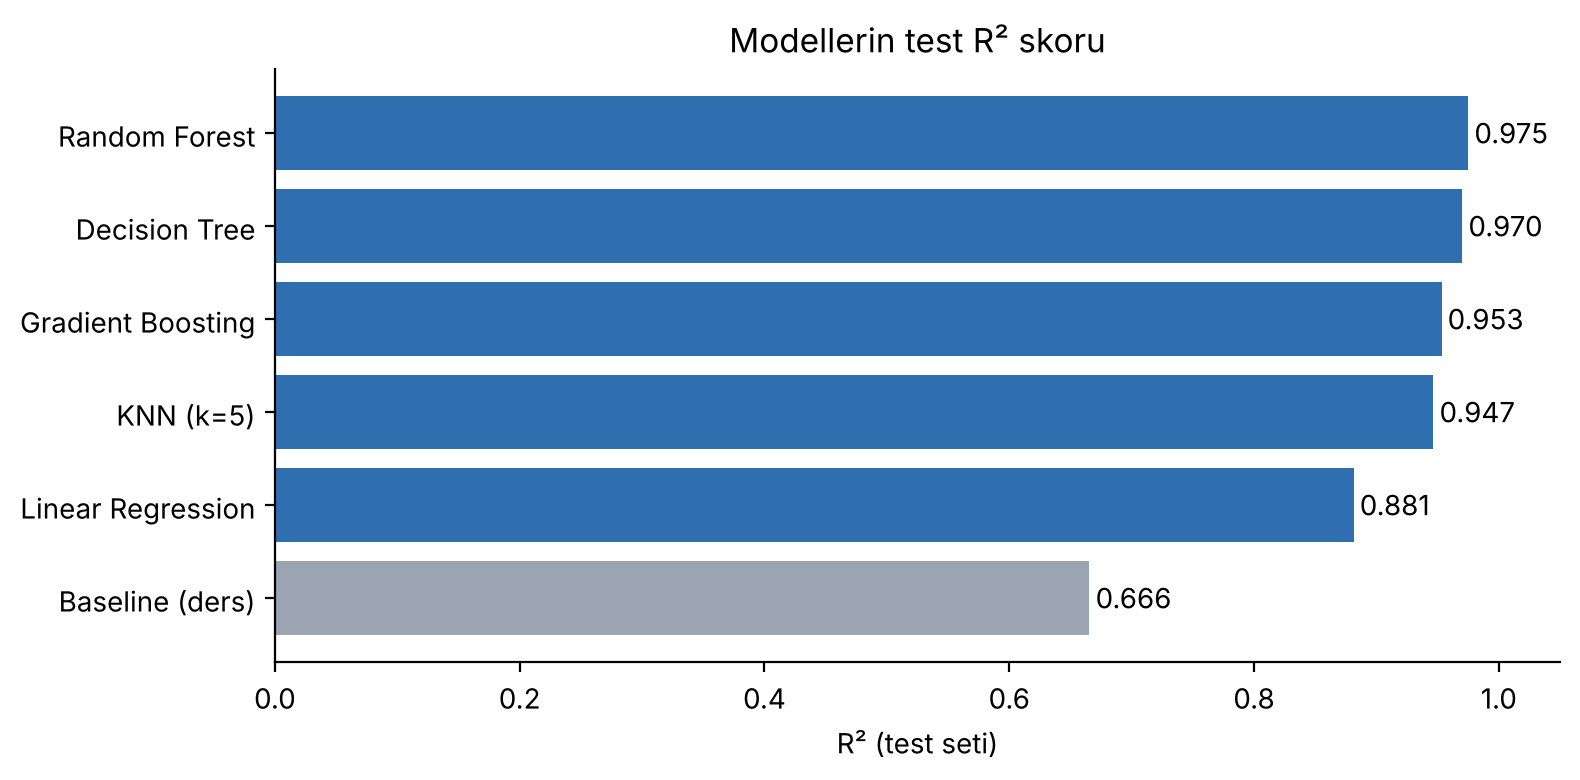

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#9aa5b1" if "Baseline" in i else "#2f6fb0" for i in results.index]
ax.barh(results.index[::-1], results["R2"][::-1], color=colors[::-1])
for i, v in enumerate(results["R2"][::-1]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center")
ax.set_xlim(0, 1.05); ax.set_xlabel("R² (test seti)")
ax.set_title("Modellerin test R² skoru")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

### 6.1 En iyi modelin (Random Forest) tahminleri

Noktalar kırmızı çizgiye ne kadar yakınsa tahmin o kadar iyi.

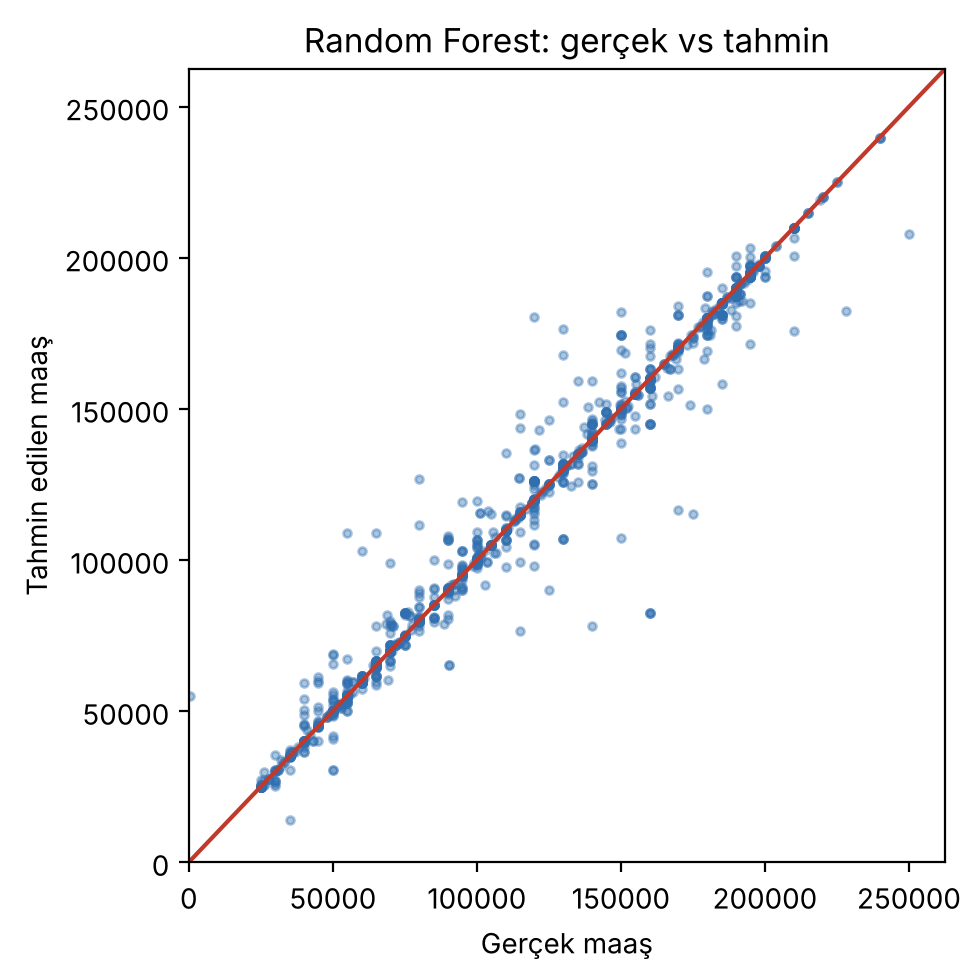

In [12]:
Xtr, Xte, ytr, yte = train_test_split(X_full, y, test_size=0.2, random_state=RANDOM_STATE)
best = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr, ytr)
p = best.predict(Xte)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(yte, p, s=8, alpha=0.4, color="#2f6fb0")
lim = [0, y.max() * 1.05]; ax.plot(lim, lim, color="#c0392b", lw=1.5)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Gerçek maaş"); ax.set_ylabel("Tahmin edilen maaş")
ax.set_title("Random Forest: gerçek vs tahmin")
plt.tight_layout(); plt.show()

### 6.2 Model neye bakıyor? (özellik önemi)

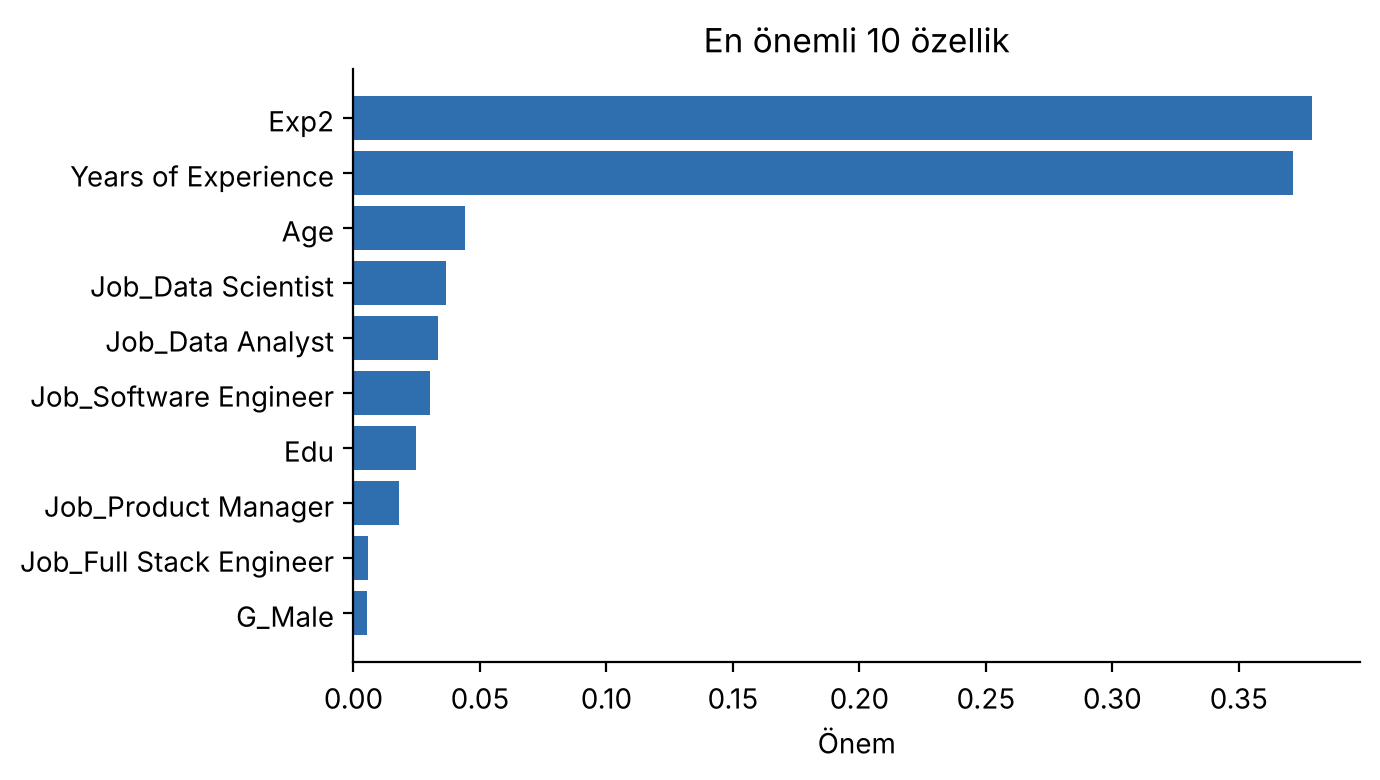

In [13]:
imp = pd.Series(best.feature_importances_, index=X_full.columns).sort_values(ascending=False).head(10)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp.index[::-1], imp.values[::-1], color="#2f6fb0")
ax.set_xlabel("Önem"); ax.set_title("En önemli 10 özellik")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Yorum:** `Exp2` ve `Years of Experience` aynı bilgiyi taşıyor (biri diğerinin karesi). Ağaç modeli önemi ikisine bölüştürmüş; toplamda **deneyim tek başına tahminin yaklaşık %75'ini belirliyor**. Ardından yaş, unvan ve eğitim geliyor. Cinsiyetin etkisi çok küçük.

## 7. Cross-validation: sonuç şans eseri mi?

Tek bir train/test ayrımı şanslı ya da şanssız olabilir. 5-fold cross-validation, veriyi 5 parçaya bölüp her parçayı sırayla test seti yapar ve 5 skorun ortalamasını verir.

In [14]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for n, m in models.items():
    s = cross_val_score(m, X_full, y, cv=kf, scoring="r2", n_jobs=-1)
    cv_rows.append({"Model": n, "CV R2 ort.": s.mean(), "CV R2 std": s.std()})
cv_df = pd.DataFrame(cv_rows).set_index("Model").sort_values("CV R2 ort.", ascending=False)
cv_df.style.format("{:.3f}")

,CV R2 ort.,CV R2 std
Model,,
Random Forest,0.976,0.003
Decision Tree,0.971,0.003
Gradient Boosting,0.951,0.003
KNN (k=5),0.940,0.006
Linear Regression,0.874,0.005


## 8. Dürüstlük kontrolü: tekrar eden satırlar (data leakage)

Veri setindeki satırların büyük çoğunluğu birebir kopya. Rastgele bölmede aynı kişinin bir kopyası train'e, diğeri test'e düşüyor. Ağaç modelleri train'deki satırı ezberleyip test'teki kopyasını "doğru tahmin ediyor". Bu, skoru olduğundan yüksek gösterir.

Gerçek performansı görmek için tekrarları silip aynı karşılaştırmayı yeniden yapıyoruz.

In [15]:
keep = ~raw.loc[df.index].duplicated()
X_dd, y_dd = X_full[keep.values], y[keep.values]
print("Tekrarlar silindikten sonra satır sayısı:", len(X_dd))

dd_rows = []
for n, m in models.items():
    s = cross_val_score(m, X_dd, y_dd, cv=kf, scoring="r2", n_jobs=-1)
    dd_rows.append({"Model": n, "CV R2 (tekrarlı veri)": cv_df.loc[n, "CV R2 ort."], "CV R2 (tekrarsız veri)": s.mean()})
dd_df = pd.DataFrame(dd_rows).set_index("Model").sort_values("CV R2 (tekrarsız veri)", ascending=False)
dd_df["Fark"] = dd_df["CV R2 (tekrarlı veri)"] - dd_df["CV R2 (tekrarsız veri)"]
dd_df.style.format("{:.3f}")

Tekrarlar silindikten sonra satır sayısı: 1787


,CV R2 (tekrarlı veri),CV R2 (tekrarsız veri),Fark
Model,,,
Random Forest,0.976,0.905,0.071
Gradient Boosting,0.951,0.903,0.048
Linear Regression,0.874,0.873,0.001
Decision Tree,0.971,0.867,0.104
KNN (k=5),0.940,0.809,0.131


## 9. Sonuç

**Ne yaptım:**
1. Dersteki baseline'ı (R² ≈ 0.666) birebir tekrar ürettim.
2. Eğitim sütunundaki yazım farklarını birleştirdim ve sıralı kodladım.
3. Silinen `Age` sütununu geri ekledim, deneyimin karesini ekledim.
4. Unvanlardan kıdem bayrakları çıkardım ve unvanı one-hot encoding ile kodladım.
5. Beş farklı regresyon modelini karşılaştırdım, sonuçları 5-fold cross-validation ile doğruladım.
6. Veri setindeki tekrar eden satırların skorları yapay olarak şişirdiğini gösterdim.

**Ne öğrendim:**
- En büyük kazanç modelden değil, **verinin doğru hazırlanmasından** geldi. Sadece encoding'i düzeltmek Linear Regression'ı 0.67'den 0.88'e çıkardı.
- En yüksek skoru Random Forest verdi (test R² 0.975, 5-fold CV 0.976 ± 0.003). Ağaç tabanlı modeller maaş ile deneyim/unvan arasındaki doğrusal olmayan ilişkileri yakalıyor.
- Veri setinin büyük kısmı tekrar eden satırlardan oluştuğu için ~0.97'lik skorlar gerçekçi değil. Tekrarlar silindiğinde Random Forest ve Gradient Boosting ~0.90 R² veriyor; gerçekçi skor bu. Yine de baseline'a (0.666) göre çok belirgin bir iyileşme.
- Linear Regression tekrarlardan neredeyse hiç etkilenmedi (0.874 → 0.873), çünkü ezberleyemiyor. En çok etkilenenler KNN ve Decision Tree oldu; ezberlemeye en yatkın modeller bunlar.